<a href="https://colab.research.google.com/github/munnamia1945/AI_ML_DL_CYS_Projects/blob/main/05-neural-network-from-scratch/neural_network_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cell 1: Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

np.random.seed(42)

print("NumPy version:", np.__version__)
print("Libraries imported successfully.")

NumPy version: 2.1.3
Libraries imported successfully.


### Cell 2: Generate and split the dataset

In [ ]:
X, y = make_moons(
    n_samples=1000,
    noise=0.20,
    random_state=42
)

X = X.astype(np.float64)
y = y.reshape(-1, 1).astype(np.float64)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Input features:", X_train.shape[1])
print("Training labels:", np.unique(y_train))

Training samples: 800
Testing samples: 200
Input features: 2
Training labels: [0. 1.]


### Cell 3: Visualize the dataset

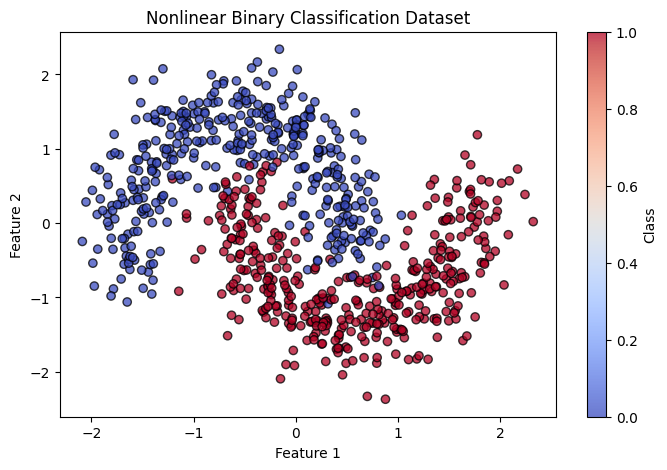

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_train[:, 0],
    X_train[:, 1],
    c=y_train.ravel(),
    cmap="coolwarm",
    edgecolors="black",
    alpha=0.75
)

plt.title("Nonlinear Binary Classification Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.colorbar(label="Class")
plt.show()

### Cell 4: Initialize weights and biases

In [ ]:
input_size = 2
hidden_size = 8
output_size = 1

W1 = np.random.randn(input_size, hidden_size) * np.sqrt(1 / input_size)
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * np.sqrt(1 / hidden_size)
b2 = np.zeros((1, output_size))

print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)

W1 shape: (2, 8)
b1 shape: (1, 8)
W2 shape: (8, 1)
b2 shape: (1, 1)


Forward propagation generates predictions from input data, while the sigmoid function keeps the output between 0 and 1




### Cell 5: Activation functions and forward pass

In [ ]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


def forward_propagation(X, W1, b1, W2, b2):
    Z1 = X @ W1 + b1
    A1 = np.tanh(Z1)

    Z2 = A1 @ W2 + b2
    A2 = sigmoid(Z2)

    cache = {
        "X": X,
        "Z1": Z1,
        "A1": A1,
        "Z2": Z2,
        "A2": A2
    }

    return A2, cache


initial_predictions, cache = forward_propagation(
    X_train, W1, b1, W2, b2
)

print("First 5 predicted probabilities:")
print(initial_predictions[:5])

First 5 predicted probabilities:
[[0.42068895]
 [0.66958214]
 [0.19507247]
 [0.70738245]
 [0.16525667]]


###Step 5 — Loss calculation
We used binary cross-entropy loss to measure the difference between predicted probabilities and actual labels

In [ ]:
def compute_loss(y_true, y_pred):
    epsilon = 1e-12
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_true * np.log(y_pred)
        + (1 - y_true) * np.log(1 - y_pred)
    )

    return loss


initial_loss = compute_loss(y_train, initial_predictions)

print("Initial training loss:", initial_loss)

Initial training loss: 1.3032989588535333


### Cell 6: Binary cross-entropy

In [ ]:
def compute_loss(y_true, y_pred):
    epsilon = 1e-12
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_true * np.log(y_pred)
        + (1 - y_true) * np.log(1 - y_pred)
    )

    return loss


initial_loss = compute_loss(y_train, initial_predictions)

print("Initial training loss:", initial_loss)

Initial training loss: 1.3032989588535333


### Cell 7: Calculate gradients
We used backpropagation to calculate the gradients of each weight and bias from the loss.

In [ ]:
def backpropagation(y_true, cache, W2):
    X = cache["X"]
    A1 = cache["A1"]
    A2 = cache["A2"]

    m = X.shape[0]

    dZ2 = (A2 - y_true) / m
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * (1 - A1 ** 2)

    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    gradients = {
        "dW1": dW1,
        "db1": db1,
        "dW2": dW2,
        "db2": db2
    }

    return gradients


gradients = backpropagation(y_train, cache, W2)

for name, value in gradients.items():
    print(name, value.shape)

dW1 (2, 8)
db1 (1, 8)
dW2 (8, 1)
db2 (1, 1)


###Cell 8: Train the neural network

In [ ]:
learning_rate = 0.05
epochs = 5000

loss_history = []

for epoch in range(epochs):
    predictions, cache = forward_propagation(
        X_train, W1, b1, W2, b2
    )

    loss = compute_loss(y_train, predictions)
    loss_history.append(loss)

    gradients = backpropagation(y_train, cache, W2)

    W1 -= learning_rate * gradients["dW1"]
    b1 -= learning_rate * gradients["db1"]

    W2 -= learning_rate * gradients["dW2"]
    b2 -= learning_rate * gradients["db2"]

    if (epoch + 1) % 500 == 0:
        print(
            f"Epoch {epoch + 1}/{epochs}, "
            f"Loss: {loss:.6f}"
        )

print("Training completed.")

Epoch 500/5000, Loss: 0.321391
Epoch 1000/5000, Loss: 0.309689
Epoch 1500/5000, Loss: 0.290011
Epoch 2000/5000, Loss: 0.257635
Epoch 2500/5000, Loss: 0.220153
Epoch 3000/5000, Loss: 0.187812
Epoch 3500/5000, Loss: 0.163432
Epoch 4000/5000, Loss: 0.145710
Epoch 4500/5000, Loss: 0.132762
Epoch 5000/5000, Loss: 0.123098
Training completed.


### Cell 9: Visualize training progress

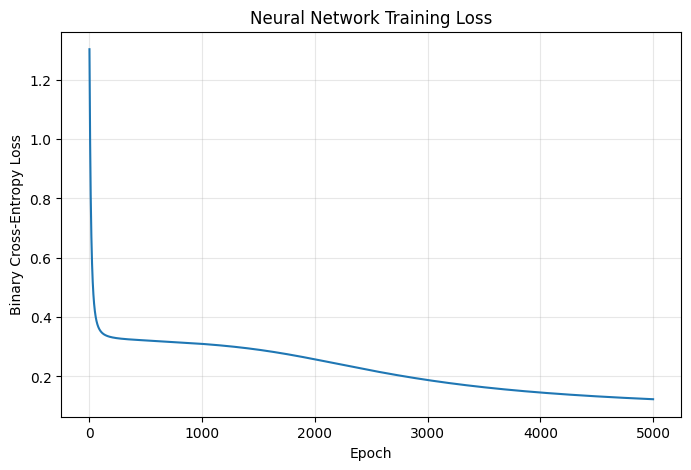

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.title("Neural Network Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.grid(True, alpha=0.3)
plt.show()

### Cell 10: Evaluate the trained model

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

test_probabilities, _ = forward_propagation(
    X_test, W1, b1, W2, b2
)

test_predictions = (test_probabilities >= 0.5).astype(int)

y_true = y_test.ravel()
y_pred = test_predictions.ravel()

print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred), 4))
print("Recall:", round(recall_score(y_true, y_pred), 4))
print("F1-score:", round(f1_score(y_true, y_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(y_true, y_pred))

Accuracy: 0.98
Precision: 0.98
Recall: 0.98
F1-score: 0.98

Confusion Matrix:
[[98  2]
 [ 2 98]]

Classification Report:
              precision    recall  f1-score   support

         0.0       0.98      0.98      0.98       100
         1.0       0.98      0.98      0.98       100

    accuracy                           0.98       200
   macro avg       0.98      0.98      0.98       200
weighted avg       0.98      0.98      0.98       200



### Cell 11: Plot the decision boundary

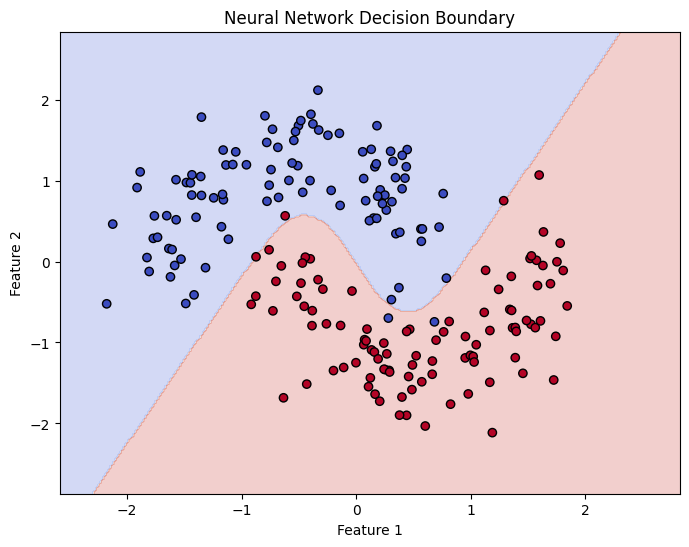

In [ ]:
x_min, x_max = X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5
y_min, y_max = X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = np.c_[xx.ravel(), yy.ravel()]

grid_probabilities, _ = forward_propagation(
    grid, W1, b1, W2, b2
)

Z = (grid_probabilities >= 0.5).astype(int).reshape(xx.shape)

plt.figure(figsize=(8, 6))

plt.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
plt.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=y_test.ravel(),
    cmap="coolwarm",
    edgecolors="black"
)

plt.title("Neural Network Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

### Cell 12: Export metrics and loss history

In [ ]:
metrics = {
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "Final Training Loss"
    ],
    "Value": [
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred),
        recall_score(y_true, y_pred),
        f1_score(y_true, y_pred),
        loss_history[-1]
    ]
}

metrics_df = pd.DataFrame(metrics)
metrics_df.to_csv("neural_network_metrics.csv", index=False)

loss_df = pd.DataFrame({
    "Epoch": np.arange(1, epochs + 1),
    "Training Loss": loss_history
})

loss_df.to_csv("neural_network_loss_history.csv", index=False)

print(metrics_df.to_string(index=False))
print("\nCSV files saved successfully.")

             Metric    Value
           Accuracy 0.980000
          Precision 0.980000
             Recall 0.980000
           F1-score 0.980000
Final Training Loss 0.123098

CSV files saved successfully.
